In [ ]:
import sys
import os

from matplotlib import pyplot as plt

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


sys.path.append(os.path.join(os.getcwd(), '../import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils

In [ ]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

In [ ]:
plot_id = 14
dims = 3


selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']
selection_n = ['DD01', 'VB02', 'SMDDR', 'AVAR']

In [ ]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
file_ids, filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path)

for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [ ]:
modes_manifold = list()
recos_manifold = list()
vars_expl_mans = list()
for trace, ds in zip(traces, discrete_states):

	pca = PCA(n_components=dims)
	trace_reduced = pca.fit_transform(trace)
	trace_reconstructed = pca.inverse_transform(trace_reduced)

	modes_manifold.append(pd.DataFrame(data=trace_reduced, columns=[f'PC{i+1}' for i in range(dims)]))
	recos_manifold.append(pd.DataFrame(data=trace_reconstructed, columns=trace.columns))

	vars_expl_mans.append(sum(pca.explained_variance_ratio_))

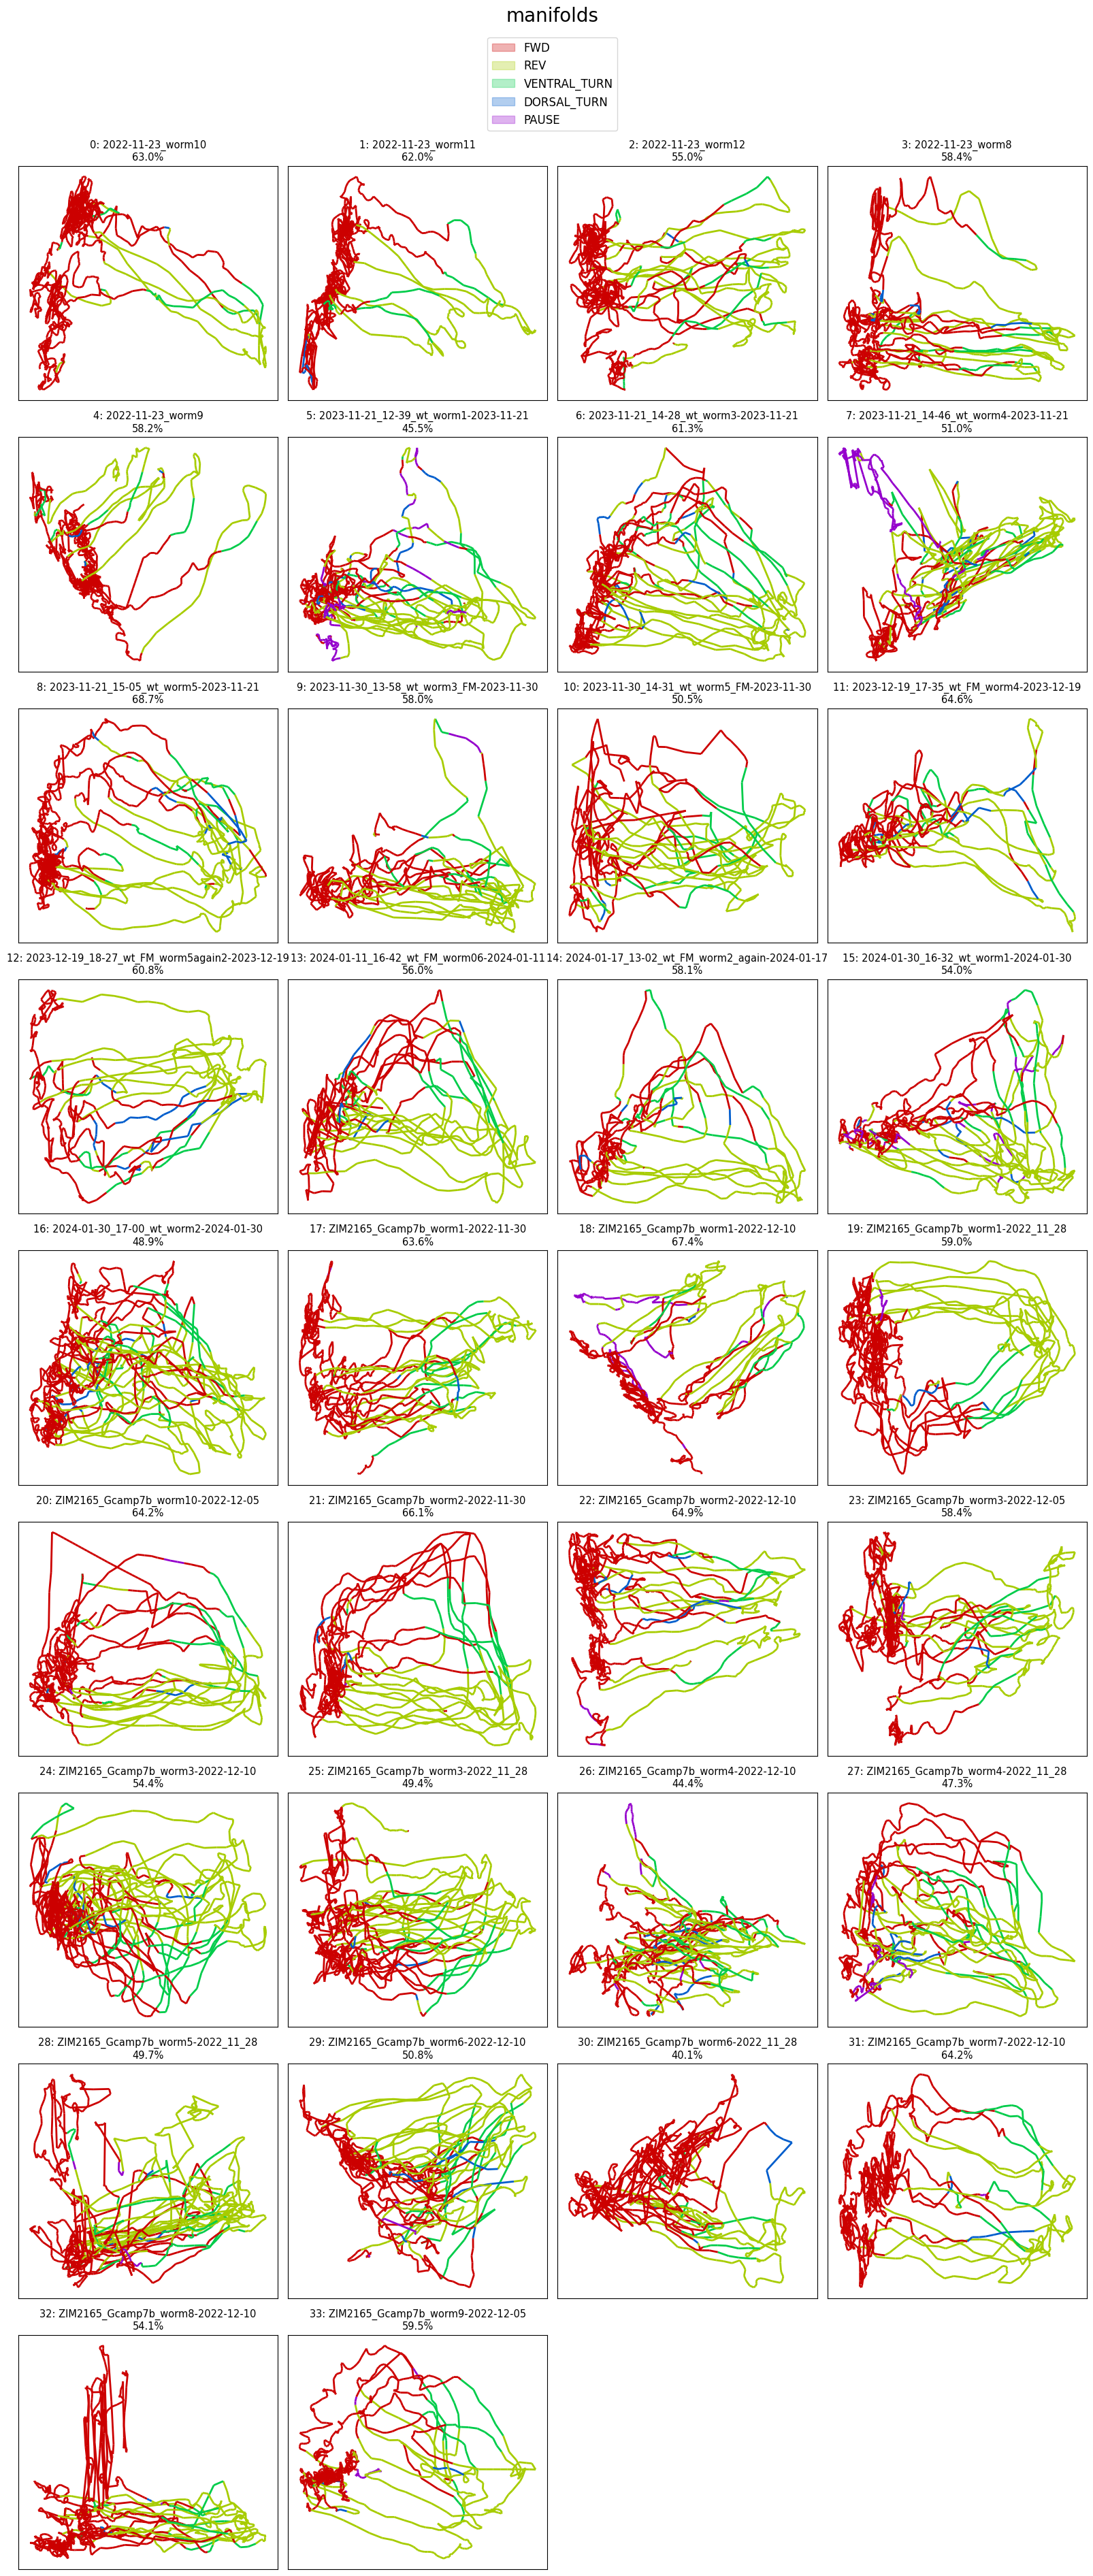

56.8%


In [19]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
						  vars_expl_mans, None,
						  save_name=f'{dims}-dim-PCA')

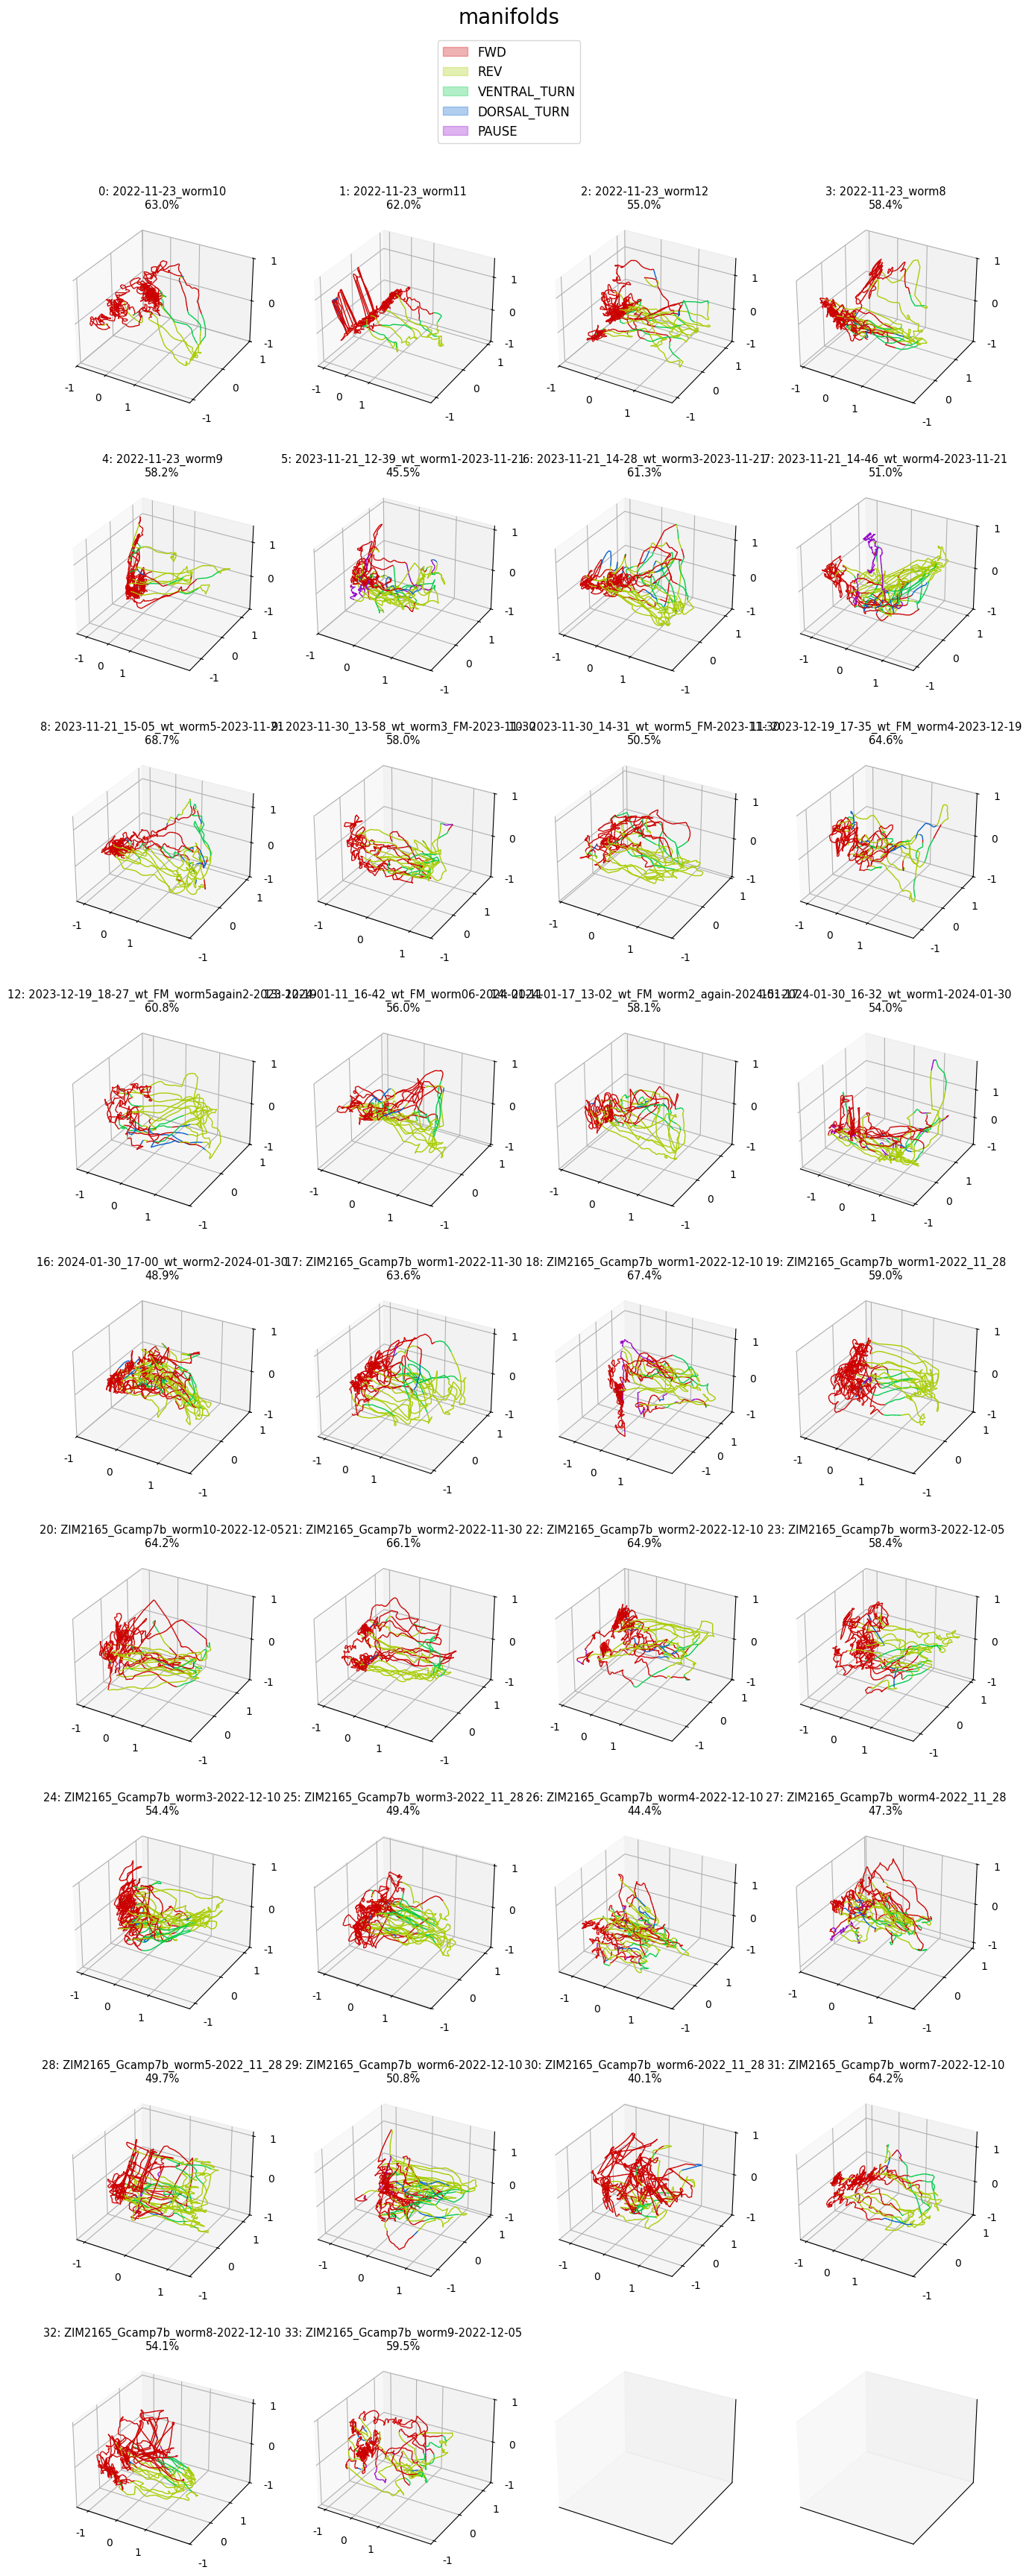

56.8%


In [20]:
plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
							 modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
							 vars_expl_mans, None,
							 save_name=f'{dims}-dim-PCA_3d')

In [ ]:
plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
								 modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
								 vars_expl_mans, None,
								 animate=True, n_plots=None,
								 save_name=f'{dims}-dim-PCA_3d')

In [ ]:
# traces_residual = [trace - trace_man for trace, trace_man in zip(traces, recos_manifold)]
#
# plot_utils.plot_traces('residuals',
# 					   discrete_states[file_ids.index(plot_id)]['REV'],
# 					   traces_residual[file_ids.index(plot_id)][selection_n],
# 					   n_plots=None, plots_per_row=1, ylimits=None)